# Advanced Data Analytics – Porto Seguro's Safe Driver Prediction

## Melanie Florine Noubissi Chimi

### Preprocessing, Logistic Regression & Neural Networks

This notebook focuses on data preprocessing, class-imbalance handling,
Logistic Regression, Neural Networks, model evaluation, dimensionality
reduction, and hyperparameter optimization.


## 1. Exploratory Data Analysis (EDA)


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [4]:
from sklearn.datasets import fetch_openml

In [5]:
data = fetch_openml(data_id=42742, as_frame=True)

/opt/anaconda3/lib/python3.11/site-packages/sklearn/datasets/_openml.py:968: FutureWarning: The default value of `parser` will change from `'liac-arff'` to `'auto'` in 1.4. You can set `parser='auto'` to silence this warning. Therefore, an `ImportError` will be raised from 1.4 if the dataset is dense and pandas is not installed. Note that the pandas parser may return different data types. See the Notes Section in fetch_openml's API doc for details.
  warn(


In [6]:
X = data.data
y = data.target

In [7]:
print("Shape of X:", X.shape)
print("Shape of y:", y.shape)

Shape of X: (595212, 57)
Shape of y: (595212,)


In [8]:
X.head()

,ps_ind_01,ps_ind_02_cat,ps_ind_03,ps_ind_04_cat,ps_ind_05_cat,ps_ind_06_bin,ps_ind_07_bin,ps_ind_08_bin,ps_ind_09_bin,ps_ind_10_bin,...,ps_calc_11,ps_calc_12,ps_calc_13,ps_calc_14,ps_calc_15_bin,ps_calc_16_bin,ps_calc_17_bin,ps_calc_18_bin,ps_calc_19_bin,ps_calc_20_bin
0,2.0,2,5.0,1,0,0,1,0,0,0,...,9.0,1.0,5.0,8.0,0,1,1,0,0,1
1,1.0,1,7.0,0,0,0,0,1,0,0,...,3.0,1.0,1.0,9.0,0,1,1,0,1,0
2,5.0,4,9.0,1,0,0,0,1,0,0,...,4.0,2.0,7.0,7.0,0,1,1,0,1,0
3,0.0,1,2.0,0,0,1,0,0,0,0,...,2.0,2.0,4.0,9.0,0,0,0,0,0,0
4,0.0,2,0.0,1,0,1,0,0,0,0,...,3.0,1.0,1.0,3.0,0,0,0,1,1,0


In [9]:
X.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 595212 entries, 0 to 595211
Data columns (total 57 columns):
 #   Column          Non-Null Count   Dtype   
---  ------          --------------   -----   
 0   ps_ind_01       595212 non-null  float64 
 1   ps_ind_02_cat   594996 non-null  category
 2   ps_ind_03       595212 non-null  float64 
 3   ps_ind_04_cat   595129 non-null  category
 4   ps_ind_05_cat   589403 non-null  category
 5   ps_ind_06_bin   595212 non-null  category
 6   ps_ind_07_bin   595212 non-null  category
 7   ps_ind_08_bin   595212 non-null  category
 8   ps_ind_09_bin   595212 non-null  category
 9   ps_ind_10_bin   595212 non-null  category
 10  ps_ind_11_bin   595212 non-null  category
 11  ps_ind_12_bin   595212 non-null  category
 12  ps_ind_13_bin   595212 non-null  category
 13  ps_ind_14       595212 non-null  float64 
 14  ps_ind_15       595212 non-null  float64 
 15  ps_ind_16_bin   595212 non-null  category
 16  ps_ind_17_bin   595212 non-null  categ

## 2. Definition of Features and Target

The dataset is divided into:

- **X (features):** explanatory variables used by the machine learning models.
- **y (target):** the variable that the models will attempt to predict.

The dataset contains **595,212 observations and 57 features**.

The target contains **595,212 values**, meaning that each observation has one corresponding target value.

In [11]:
y.value_counts()

target
0    573518
1     21694
Name: count, dtype: int64

In [12]:
y.value_counts(normalize=True) * 100

target
0    96.355248
1     3.644752
Name: proportion, dtype: float64

### Missing Values Analysis

Missing values are detected using `isna()`. Since the number of missing
observations differs considerably between features, both the absolute
number and the percentage of missing values are calculated.

This analysis will be used to determine an appropriate imputation
strategy during preprocessing.

In [14]:
missing_count = X.isna().sum()

missing_percent = (missing_count / len(X)) * 100

missing_summary = pd.DataFrame({
    "Missing_Count": missing_count,
    "Missing_Percent": missing_percent
})

missing_summary = missing_summary[
    missing_summary["Missing_Count"] > 0
].sort_values("Missing_Percent", ascending=False)

missing_summary

,Missing_Count,Missing_Percent
ps_car_03_cat,411231,69.089837
ps_car_05_cat,266551,44.782531
ps_reg_03,107772,18.106490
ps_car_14,42620,7.160474
ps_car_07_cat,11489,1.930237
ps_ind_05_cat,5809,0.975955
ps_car_09_cat,569,0.095596
ps_ind_02_cat,216,0.036290
ps_car_01_cat,107,0.017977
ps_ind_04_cat,83,0.013945


### Feature Type Identification

The features are grouped according to the naming convention of the
Porto Seguro dataset.

- Features ending in `_cat` are treated as categorical features.
- Features ending in `_bin` are treated as binary features.
- The remaining features are initially grouped as numerical/other features.

This distinction is important because different feature types may
require different preprocessing strategies.

In [16]:
categorical_features = [
    col for col in X.columns if col.endswith("_cat")
]

binary_features = [
    col for col in X.columns if col.endswith("_bin")
]

numerical_features = [
    col for col in X.columns
    if not col.endswith("_cat") and not col.endswith("_bin")
]
print("Categorical features:", len(categorical_features))
print("Binary features:", len(binary_features))
print("Numerical/other features:", len(numerical_features))
print("Total:", len(categorical_features) + len(binary_features) + len(numerical_features))

Categorical features: 14
Binary features: 17
Numerical/other features: 26
Total: 57


In [17]:
categorical_missing = X[categorical_features].isna().sum()

categorical_missing = categorical_missing[
    categorical_missing > 0
].sort_values(ascending=False)

categorical_missing

ps_car_03_cat    411231
ps_car_05_cat    266551
ps_car_07_cat     11489
ps_ind_05_cat      5809
ps_car_09_cat       569
ps_ind_02_cat       216
ps_car_01_cat       107
ps_ind_04_cat        83
ps_car_02_cat         5
dtype: int64

In [18]:
numerical_missing = X[numerical_features].isna().sum()

numerical_missing = numerical_missing[
    numerical_missing > 0
].sort_values(ascending=False)

numerical_missing

ps_reg_03    107772
ps_car_14     42620
ps_car_11         5
ps_car_12         1
dtype: int64

## 3. Train-Test Split

Before preprocessing the data, the dataset is divided into training and test sets.

The training set will be used to learn the preprocessing parameters and train the models, while the test set will remain unseen and will be used for the final evaluation.

Because the target variable is highly imbalanced, stratified sampling is used to preserve the class distribution.

In [20]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [21]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (476169, 57)
X_test: (119043, 57)
y_train: (476169,)
y_test: (119043,)


## 4. Missing Value Imputation

### 4.1 Numerical Features — Median Imputation

A median imputation strategy is first applied to the numerical features.

The imputer is fitted exclusively on the training data to prevent data
leakage. Therefore, the median of each numerical feature is learned from
`X_train` only.

The learned median values will subsequently be used to transform both
the training and test datasets.

In [23]:
from sklearn.impute import SimpleImputer
numeric_imputer = SimpleImputer(strategy="median")
numeric_imputer.fit(X_train[numerical_features])
median_values = pd.Series(
    numeric_imputer.statistics_,
    index=numerical_features
)

median_values[numerical_missing.index]

ps_reg_03    0.801951
ps_car_14    0.373497
ps_car_11    3.000000
ps_car_12    0.374166
dtype: float64

In [24]:
X_train_imputed = X_train.copy()
X_test_imputed = X_test.copy()

X_train_imputed[numerical_features] = numeric_imputer.transform(
    X_train[numerical_features]
)

X_test_imputed[numerical_features] = numeric_imputer.transform(
    X_test[numerical_features] 
)

print(
    "Numerical missing values in train:",
    X_train_imputed[numerical_features].isna().sum().sum()
)

print(
    "Numerical missing values in test:",
    X_test_imputed[numerical_features].isna().sum().sum()
)

Numerical missing values in train: 0
Numerical missing values in test: 0


**Observation:**

The numerical imputer learned one median value for each numerical
feature from the training set.

The same learned values were then used to impute missing numerical
values in both the training and test sets, preventing information
leakage from the test data.

### 4.2 Categorical Features — Constant Imputation

Categorical variables are stored as categories rather than continuous
quantities. Missing values are therefore represented by a separate
`"Missing"` category. The imputer is fitted on the training data only.


In [27]:
categorical_imputer = SimpleImputer(
    strategy="constant",
    fill_value="Missing"
)
categorical_imputer.fit(
    X_train[categorical_features].astype("object")
)

SimpleImputer(fill_value='Missing', strategy='constant')

In [28]:
X_train_imputed[categorical_features] = categorical_imputer.transform(
    X_train[categorical_features].astype("object")
)

X_test_imputed[categorical_features] = categorical_imputer.transform(
    X_test[categorical_features].astype("object")
)
print(
    "Categorical missing values in train:",
    X_train_imputed[categorical_features].isna().sum().sum()
)

print(
    "Categorical missing values in test:",
    X_test_imputed[categorical_features].isna().sum().sum()
)

Categorical missing values in train: 0
Categorical missing values in test: 0


## 5. Categorical Encoding

### One-Hot Encoding

Categorical features must be converted into a numerical representation
before they can be used by the machine learning models.

One-Hot Encoding is used to create binary indicator features for each
category without introducing an artificial numerical order.

The encoder is fitted exclusively on the training data to prevent data
leakage. Unknown categories in the test data are ignored.

In [30]:
from sklearn.preprocessing import OneHotEncoder

categorical_encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=True
)
categorical_encoder.fit(
    X_train_imputed[categorical_features]
)


OneHotEncoder(handle_unknown='ignore')

In [31]:
encoded_feature_names = categorical_encoder.get_feature_names_out(
    categorical_features
)

print("Categorical features before encoding:", len(categorical_features))
print("Categorical features after encoding:", len(encoded_feature_names))

Categorical features before encoding: 14
Categorical features after encoding: 184


In [32]:
X_train_cat_encoded = categorical_encoder.transform(
    X_train_imputed[categorical_features]
)

X_test_cat_encoded = categorical_encoder.transform(
    X_test_imputed[categorical_features]
)

print("Train categorical encoded:", X_train_cat_encoded.shape)
print("Test categorical encoded:", X_test_cat_encoded.shape)

Train categorical encoded: (476169, 184)
Test categorical encoded: (119043, 184)


**Observation:**

After applying One-Hot Encoding, the 14 original categorical features
were transformed into 184 binary features.

The training set contains 476,169 observations and the test set contains
119,043 observations. Both datasets have the same 184 encoded categorical
features.

The encoder was fitted only on the training data and then used to
transform both training and test data, preventing data leakage.

## 6. Numerical Feature Scaling

### Standardization

Numerical features are standardized using `StandardScaler`.

Standardization transforms each numerical feature by subtracting its
training mean and dividing by its training standard deviation.

The scaler is fitted exclusively on the training data to prevent
data leakage. The same learned parameters will then be applied to
both the training and test sets.

In [35]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

scaler.fit(
    X_train_imputed[numerical_features]
)
X_train_num_scaled = scaler.transform(
    X_train_imputed[numerical_features]
)

X_test_num_scaled = scaler.transform(
    X_test_imputed[numerical_features]
)
print("Train numerical scaled:", X_train_num_scaled.shape)
print("Test numerical scaled:", X_test_num_scaled.shape)

Train numerical scaled: (476169, 26)
Test numerical scaled: (119043, 26)


**Observation:**

After standardization, the numerical feature matrices contain 26 features
for both the training and test sets.

StandardScaler changes the scale of the numerical values but does not
change the number of features.

The scaler was fitted only on the training data and the same learned
parameters were applied to the test data to prevent data leakage.

## 7. Binary Feature Preparation

Binary features are converted to floating-point values so that they can
be combined with the scaled numerical features and the one-hot encoded
categorical features.


In [38]:
X_train_bin = X_train_imputed[binary_features].astype(float).to_numpy()
X_test_bin = X_test_imputed[binary_features].astype(float).to_numpy()

print("Train binary:", X_train_bin.shape)
print("Test binary:", X_test_bin.shape)


Train binary: (476169, 17)
Test binary: (119043, 17)


## 8. Final Feature Assembly


In [40]:
from scipy import sparse
X_train_final = sparse.hstack([
    sparse.csr_matrix(X_train_num_scaled),
    sparse.csr_matrix(X_train_bin),
    X_train_cat_encoded
]).tocsr()
X_test_final = sparse.hstack([
    sparse.csr_matrix(X_test_num_scaled),
    sparse.csr_matrix(X_test_bin),
    X_test_cat_encoded
]).tocsr()
print("X_train_final:", X_train_final.shape)
print("X_test_final:", X_test_final.shape)

X_train_final: (476169, 227)
X_test_final: (119043, 227)


The preprocessed numerical, binary and encoded categorical features are
combined into one sparse matrix. The resulting training and test matrices
contain the same 227 features and are ready for model training.


## 9. Baseline Logistic Regression


In [43]:
from sklearn.linear_model import LogisticRegression
log_reg = LogisticRegression(
    max_iter=1000,
    random_state=42
)
log_reg.fit(X_train_final, y_train)

LogisticRegression(max_iter=1000, random_state=42)

In [44]:
y_pred = log_reg.predict(X_test_final)

y_proba = log_reg.predict_proba(X_test_final)[:, 1]

In [45]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, pos_label="1", zero_division=0))
print("Recall:", recall_score(y_test, y_pred, pos_label="1", zero_division=0))
print("F1-score:", f1_score(y_test, y_pred, pos_label="1", zero_division=0))
print("ROC-AUC:", roc_auc_score(y_test, y_proba))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred, labels=["0", "1"]))

Accuracy: 0.9635341851263829
Precision: 0.375
Recall: 0.0006914035492048859
F1-score: 0.0013802622498274675
ROC-AUC: 0.6315528826628671

Confusion Matrix:
[[114699      5]
 [  4336      3]]


### Baseline Logistic Regression — Evaluation

The baseline Logistic Regression achieves an accuracy of approximately
96.35%. However, this result is misleading because the target variable
is highly imbalanced, with approximately 96.36% of observations belonging
to class 0.

The confusion matrix shows that only 3 out of 4,339 positive observations
were correctly identified, resulting in an extremely low recall.

Therefore, accuracy is not an appropriate metric to evaluate the model
in isolation.

The ROC-AUC score of approximately 0.632 indicates that the model still
has some ability to rank positive observations above negative ones,
although the default classification threshold of 0.5 leads to very poor
detection of the minority class.

Further steps should therefore address class imbalance and/or investigate
the classification threshold.


## 10. Handling Class Imbalance with Logistic Regression


In [48]:

log_reg_balanced = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

log_reg_balanced.fit(X_train_final, y_train)

y_pred_balanced = log_reg_balanced.predict(X_test_final)

y_proba_balanced = log_reg_balanced.predict_proba(
    X_test_final
)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred_balanced))

print(
    "Precision:",
    precision_score(
        y_test,
        y_pred_balanced,
        pos_label="1",
        zero_division=0
    )
)

print(
    "Recall:",
    recall_score(
        y_test,
        y_pred_balanced,
        pos_label="1",
        zero_division=0
    )
)

print(
    "F1-score:",
    f1_score(
        y_test,
        y_pred_balanced,
        pos_label="1",
        zero_division=0
    )
)

print(
    "ROC-AUC:",
    roc_auc_score(y_test, y_proba_balanced)
)

print("\nConfusion Matrix:")

print(
    confusion_matrix(
        y_test,
        y_pred_balanced,
        labels=["0", "1"]
    )
)


Accuracy: 0.6266139126198097
Precision: 0.053897143874010144
Recall: 0.5584235999078129
F1-score: 0.09830611623896947
ROC-AUC: 0.6311516716184516

Confusion Matrix:
[[72171 42533]
 [ 1916  2423]]


### Handling Class Imbalance with Class Weights

A second Logistic Regression model was trained using
`class_weight="balanced"` to give greater importance to the minority class.

Compared with the baseline model, recall increased dramatically from
approximately 0.07% to 55.84%, meaning that the model now identifies
2,423 of the 4,339 positive observations.

However, this improvement comes at the cost of a large increase in false
positives, resulting in a precision of only 5.39% and a lower accuracy.

Interestingly, ROC-AUC remains approximately 0.63 for both models.
Therefore, class weighting mainly changes the classification trade-off
rather than substantially improving the model's ranking ability.

This illustrates why accuracy alone is inappropriate for evaluating
highly imbalanced classification problems.

## 11. Threshold and Curve Analysis


### 11.1 ROC Curve


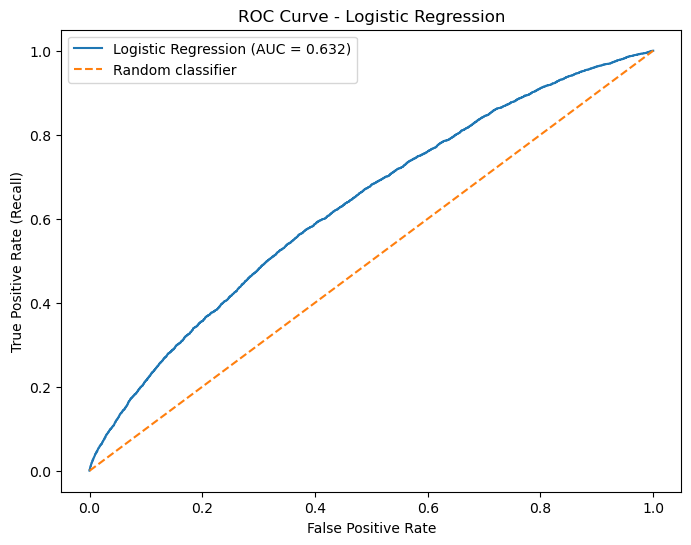

In [52]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

fpr, tpr, thresholds = roc_curve(
    y_test,
    y_proba,
    pos_label="1"
)

auc = roc_auc_score(y_test, y_proba)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Logistic Regression (AUC = {auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curve - Logistic Regression")
plt.legend()
plt.show()

### 11.2 Classification Threshold Analysis


In [54]:
thresholds_to_test = [0.50, 0.30, 0.20, 0.10, 0.05]

for threshold in thresholds_to_test:
    
    y_pred_threshold = np.where(
        y_proba >= threshold,
        "1",
        "0"
    )
    
    precision = precision_score(
        y_test,
        y_pred_threshold,
        pos_label="1",
        zero_division=0
    )
    
    recall = recall_score(
        y_test,
        y_pred_threshold,
        pos_label="1"
    )
    
    f1 = f1_score(
        y_test,
        y_pred_threshold,
        pos_label="1"
    )
    
    print(f"Threshold: {threshold}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1-score: {f1:.4f}")
    print("--------------------")

Threshold: 0.5
Precision: 0.3750
Recall: 0.0007
F1-score: 0.0014
--------------------
Threshold: 0.3
Precision: 0.5000
Recall: 0.0021
F1-score: 0.0041
--------------------
Threshold: 0.2
Precision: 0.2241
Recall: 0.0030
F1-score: 0.0059
--------------------
Threshold: 0.1
Precision: 0.1224
Recall: 0.0426
F1-score: 0.0632
--------------------
Threshold: 0.05
Precision: 0.0664
Recall: 0.3100
F1-score: 0.1093
--------------------


### 11.3 Precision–Recall Curve


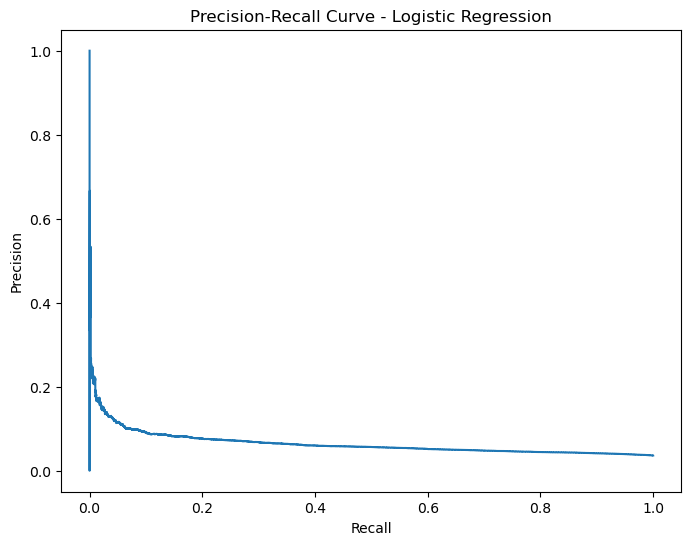

In [56]:
from sklearn.metrics import precision_recall_curve
import matplotlib.pyplot as plt

precision, recall, pr_thresholds = precision_recall_curve(
    y_test,
    y_proba,
    pos_label="1"
)

plt.figure(figsize=(8, 6))

plt.plot(recall, precision)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - Logistic Regression")

plt.show()

### Precision-Recall Analysis

The Precision-Recall curve highlights the difficulty of identifying the
minority class.

As recall increases, precision decreases substantially, indicating that
detecting more positive cases requires accepting a larger number of false
positives.

This trade-off is particularly important because the positive class
represents only about 3.64% of the observations.

Therefore, the classification threshold should not be selected solely
based on the default value of 0.5. In a real insurance setting, threshold
selection should also consider the business costs associated with false
negatives and false positives.

## 12. Neural Network

A Multi-Layer Perceptron is used to test whether a non-linear model can
improve predictive performance compared with Logistic Regression.


### 12.1 Baseline Neural Network


In [60]:

from sklearn.neural_network import MLPClassifier
mlp = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation="relu",
    solver="adam",
    max_iter=50,
    random_state=42,
    early_stopping=True
)
mlp.fit(X_train_final, y_train)
y_pred_mlp = mlp.predict(X_test_final)

y_proba_mlp = mlp.predict_proba(X_test_final)[:, 1]
print("Accuracy:", accuracy_score(y_test, y_pred_mlp))
print(
    "Precision:",
    precision_score(y_test, y_pred_mlp, pos_label="1", zero_division=0)
)
print(
    "Recall:",
    recall_score(y_test, y_pred_mlp, pos_label="1", zero_division=0)
)
print(
    "F1-score:",
    f1_score(y_test, y_pred_mlp, pos_label="1", zero_division=0)
)
print(
    "ROC-AUC:",
    roc_auc_score(y_test, y_proba_mlp)
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_test,
        y_pred_mlp,
        labels=["0", "1"]
    )
)

Accuracy: 0.9635509857782482
Precision: 0.0
Recall: 0.0
F1-score: 0.0
ROC-AUC: 0.6285663846904795

Confusion Matrix:
[[114704      0]
 [  4339      0]]


### 12.2 Random Undersampling


In [62]:
import numpy as np

# Indices of each class in the training set
idx_class_0 = np.where(y_train.to_numpy() == "0")[0]
idx_class_1 = np.where(y_train.to_numpy() == "1")[0]

# Randomly select the same number of class 0 observations
rng = np.random.default_rng(42)

idx_class_0_sampled = rng.choice(
    idx_class_0,
    size=len(idx_class_1),
    replace=False
)

# Combine both classes
balanced_indices = np.concatenate([
    idx_class_0_sampled,
    idx_class_1
])

# Shuffle the selected indices
rng.shuffle(balanced_indices)

# Create balanced training data
X_train_balanced = X_train_final[balanced_indices]

y_train_balanced = y_train.iloc[balanced_indices]
print("X_train_balanced:", X_train_balanced.shape)

print("\nClass distribution:")
print(y_train_balanced.value_counts())

X_train_balanced: (34710, 227)

Class distribution:
target
0    17355
1    17355
Name: count, dtype: int64


### 12.3 Neural Network after Undersampling


In [64]:
mlp_balanced = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation="relu",
    solver="adam",
    max_iter=50,
    random_state=42,
    early_stopping=True
)
mlp_balanced.fit(
    X_train_balanced,
    y_train_balanced
)

MLPClassifier(early_stopping=True, hidden_layer_sizes=(64, 32), max_iter=50,
              random_state=42)

In [65]:
y_pred_mlp_balanced = mlp_balanced.predict(
    X_test_final
)

y_proba_mlp_balanced = mlp_balanced.predict_proba(
    X_test_final
)[:, 1]

In [66]:
print(
    "Accuracy:",
    accuracy_score(y_test, y_pred_mlp_balanced)
)

print(
    "Precision:",
    precision_score(
        y_test,
        y_pred_mlp_balanced,
        pos_label="1",
        zero_division=0
    )
)

print(
    "Recall:",
    recall_score(
        y_test,
        y_pred_mlp_balanced,
        pos_label="1",
        zero_division=0
    )
)

print(
    "F1-score:",
    f1_score(
        y_test,
        y_pred_mlp_balanced,
        pos_label="1",
        zero_division=0
    )
)

print(
    "ROC-AUC:",
    roc_auc_score(
        y_test,
        y_proba_mlp_balanced
    )
)

print("\nConfusion Matrix:")

print(
    confusion_matrix(
        y_test,
        y_pred_mlp_balanced,
        labels=["0", "1"]
    )
)

Accuracy: 0.6565022722881648
Precision: 0.05317588381986211
Recall: 0.5012675731735423
F1-score: 0.09615172078424436
ROC-AUC: 0.6169875633035131

Confusion Matrix:
[[75977 38727]
 [ 2164  2175]]


## 13. Scikit-Learn Preprocessing Pipeline

For cross-validation and model optimization, preprocessing is grouped
with the classifier in a Scikit-Learn Pipeline. This ensures that
imputation, scaling and encoding are learned within the training data
used by each fitting procedure.


In [68]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression

# Numerical preprocessing
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    (
        "to_object",
        FunctionTransformer(
            lambda df: df.astype("object"),
            validate=False
        )
    ),
    (
        "imputer",
        SimpleImputer(
            strategy="constant",
            fill_value="Missing"
        )
    ),
    (
        "encoder",
        OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=True
        )
    )
])

# Binary preprocessing
binary_pipeline = Pipeline([
    (
        "to_float",
        FunctionTransformer(
            lambda df: df.astype(float),
            validate=False
        )
    )
])

# Combine preprocessing
preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features),
    ("bin", binary_pipeline, binary_features)
])

# Final pipeline
pipeline_log_reg = Pipeline([
    ("preprocessor", preprocessor),
    (
        "model",
        LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        )
    )
])

pipeline_log_reg

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['ps_ind_01', 'ps_ind_03',
                                                   'ps_ind_14', 'ps_ind_15',
                                                   'ps_reg_01', 'ps_reg_02',
                                                   'ps_reg_03', 'ps_car_11',
                                                   'ps_car_12', 'ps_car_13',
                                                   'ps_car_14', 'ps_car_15',
                                                   'ps_calc_01', 'ps_calc_02',
                                                   'ps_calc_03', 'ps_...
                                                   'ps_ind_07_bin',
                                                   'ps_ind_08_bin',
                                                   'ps_ind_09_bin',
                                                   'ps_ind_10_bin',
                                                   'ps_ind_11_bin',
                                                   'ps_ind_12_bin',
                                                   'ps_ind_13_bin',
                                                   'ps_ind_16_bin',
                                                   'ps_ind_17_bin',
                                                   'ps_ind_18_bin',
                                                   'ps_calc_15_bin',
                                                   'ps_calc_16_bin',
                                                   'ps_calc_17_bin',
                                                   'ps_calc_18_bin',
                                                   'ps_calc_19_bin',
                                                   'ps_calc_20_bin'])])),
                ('model',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])

## 14. Learning Curve


In [70]:
from sklearn.model_selection import train_test_split

X_dev, _, y_dev, _ = train_test_split(
    X_train,
    y_train,
    train_size=100000,
    random_state=42,
    stratify=y_train
)

print("Development sample:", X_dev.shape)
print("\nTarget distribution:")
print(y_dev.value_counts(normalize=True))


Development sample: (100000, 57)

Target distribution:
target
0    0.96355
1    0.03645
Name: proportion, dtype: float64


In [71]:
from sklearn.model_selection import learning_curve

train_sizes, train_scores, validation_scores = learning_curve(
    estimator=pipeline_log_reg,
    X=X_dev,
    y=y_dev,
    cv=3,
    scoring="roc_auc",
    train_sizes=[0.1, 0.25, 0.5, 0.75, 1.0],
    n_jobs=1
)

train_mean = train_scores.mean(axis=1)
validation_mean = validation_scores.mean(axis=1)

print("Training ROC-AUC:")
print(train_mean)

print("\nValidation ROC-AUC:")
print(validation_mean)

Training ROC-AUC:
[0.78979466 0.70562104 0.66975395 0.65857544 0.64939537]

Validation ROC-AUC:
[0.55596254 0.5792951  0.59804352 0.60471512 0.60971291]


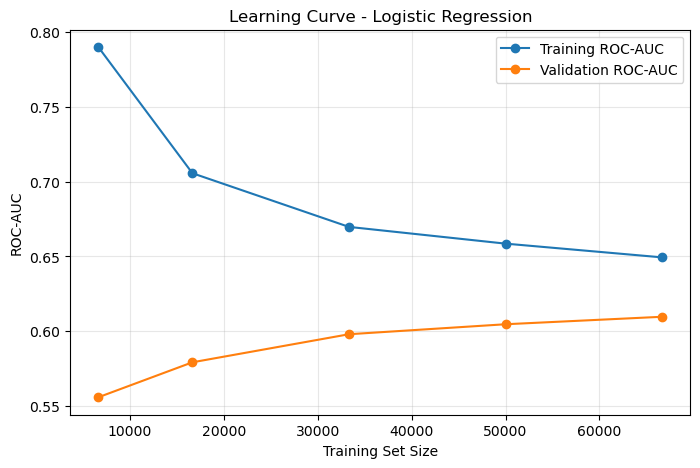

In [72]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    train_sizes,
    train_mean,
    marker="o",
    label="Training ROC-AUC"
)

plt.plot(
    train_sizes,
    validation_mean,
    marker="o",
    label="Validation ROC-AUC"
)

plt.xlabel("Training Set Size")
plt.ylabel("ROC-AUC")
plt.title("Learning Curve - Logistic Regression")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

**Interpretation:** With small training samples, the gap between training
and validation ROC-AUC is large. As more observations are used, training
ROC-AUC decreases while validation ROC-AUC increases, indicating improved
generalization and showing that the model benefits from additional data.


## 15. Dimensionality Reduction — TruncatedSVD


In [75]:
from sklearn.decomposition import TruncatedSVD
from sklearn.pipeline import Pipeline

pipeline_svd = Pipeline([
    ("preprocessor", preprocessor),

    (
        "svd",
        TruncatedSVD(
            n_components=50,
            random_state=42
        )
    ),

    (
        "model",
        LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        )
    )
])

pipeline_svd

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['ps_ind_01', 'ps_ind_03',
                                                   'ps_ind_14', 'ps_ind_15',
                                                   'ps_reg_01', 'ps_reg_02',
                                                   'ps_reg_03', 'ps_car_11',
                                                   'ps_car_12', 'ps_car_13',
                                                   'ps_car_14', 'ps_car_15',
                                                   'ps_calc_01', 'ps_calc_02',
                                                   'ps_calc_03', 'ps_...
                                                   'ps_ind_10_bin',
                                                   'ps_ind_11_bin',
                                                   'ps_ind_12_bin',
                                                   'ps_ind_13_bin',
                                                   'ps_ind_16_bin',
                                                   'ps_ind_17_bin',
                                                   'ps_ind_18_bin',
                                                   'ps_calc_15_bin',
                                                   'ps_calc_16_bin',
                                                   'ps_calc_17_bin',
                                                   'ps_calc_18_bin',
                                                   'ps_calc_19_bin',
                                                   'ps_calc_20_bin'])])),
                ('svd', TruncatedSVD(n_components=50, random_state=42)),
                ('model',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])

In [76]:
from sklearn.model_selection import cross_val_score

scores_without_svd = cross_val_score(
    pipeline_log_reg,
    X_dev,
    y_dev,
    cv=3,
    scoring="roc_auc",
    n_jobs=1
)

scores_with_svd = cross_val_score(
    pipeline_svd,
    X_dev,
    y_dev,
    cv=3,
    scoring="roc_auc",
    n_jobs=1
)

print("ROC-AUC without dimensionality reduction:")
print(scores_without_svd)

print("\nMean ROC-AUC without dimensionality reduction:")
print(scores_without_svd.mean())

print("\nROC-AUC with TruncatedSVD:")
print(scores_with_svd)

print("\nMean ROC-AUC with TruncatedSVD:")
print(scores_with_svd.mean())

ROC-AUC without dimensionality reduction:
[0.61366644 0.61165486 0.6038735 ]

Mean ROC-AUC without dimensionality reduction:
0.6097315992551818

ROC-AUC with TruncatedSVD:
[0.61324006 0.60653785 0.61339892]

Mean ROC-AUC with TruncatedSVD:
0.6110589450485895


**Interpretation:** TruncatedSVD produced only a very small improvement in
mean cross-validation ROC-AUC (approximately 0.6111 versus 0.6097).
Therefore, dimensionality reduction was tested but did not provide a
substantial performance gain.


## 16. Hyperparameter Optimization


In [79]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "model__C": [0.01, 0.1, 1, 10]
}

grid_search = GridSearchCV(
    estimator=pipeline_log_reg,
    param_grid=param_grid,
    scoring="roc_auc",
    cv=3,
    n_jobs=1,
    verbose=1
)

grid_search.fit(X_dev, y_dev)

print("Best parameters:")
print(grid_search.best_params_)

print("\nBest cross-validation ROC-AUC:")
print(grid_search.best_score_)

Fitting 3 folds for each of 4 candidates, totalling 12 fits
Best parameters:
{'model__C': 0.01}

Best cross-validation ROC-AUC:
0.6156159653228858


GridSearchCV selected `C=0.01`. The best mean cross-validation ROC-AUC
was approximately 0.6156, a modest improvement over the untuned pipeline.


## 17. Final Optimized Logistic Regression


In [82]:
# Final optimized Logistic Regression

final_model = Pipeline([
    ("preprocessor", preprocessor),
    (
        "model",
        LogisticRegression(
            C=0.01,
            max_iter=1000,
            class_weight="balanced",
            random_state=42
        )
    )
])

final_model.fit(X_train, y_train)

y_pred_final = final_model.predict(X_test)
y_proba_final = final_model.predict_proba(X_test)[:, 1]

print("Final model trained successfully.")

Final model trained successfully.


In [83]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

accuracy_final = accuracy_score(y_test, y_pred_final)

precision_final = precision_score(
    y_test,
    y_pred_final,
    pos_label="1",
    zero_division=0
)

recall_final = recall_score(
    y_test,
    y_pred_final,
    pos_label="1",
    zero_division=0
)

f1_final = f1_score(
    y_test,
    y_pred_final,
    pos_label="1",
    zero_division=0
)

roc_auc_final = roc_auc_score(
    y_test,
    y_proba_final
)

gini_final = 2 * roc_auc_final - 1

cm_final = confusion_matrix(
    y_test,
    y_pred_final,
    labels=["0", "1"]
)

print("FINAL MODEL RESULTS")
print("-------------------")
print(f"Accuracy: {accuracy_final:.4f}")
print(f"Precision: {precision_final:.4f}")
print(f"Recall: {recall_final:.4f}")
print(f"F1-score: {f1_final:.4f}")
print(f"ROC-AUC: {roc_auc_final:.4f}")
print(f"Normalized Gini: {gini_final:.4f}")

print("\nConfusion Matrix:")
print(cm_final)

FINAL MODEL RESULTS
-------------------
Accuracy: 0.6263
Precision: 0.0541
Recall: 0.5607
F1-score: 0.0986
ROC-AUC: 0.6317
Normalized Gini: 0.2634

Confusion Matrix:
[[72127 42577]
 [ 1906  2433]]


## 18. Cross-Validation with Normalized Gini


In [85]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv_scheme = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

final_auc_cv = cross_val_score(
    final_model,
    X_train,
    y_train,
    cv=cv_scheme,
    scoring="roc_auc",
    n_jobs=1
)

final_gini_cv = 2 * final_auc_cv - 1

print("Final ROC-AUC per fold:")
print(final_auc_cv)

print("\nFinal Normalized Gini per fold:")
print(final_gini_cv)

print("\nMean Final Normalized Gini:")
print(final_gini_cv.mean())

print("\nStandard deviation:")
print(final_gini_cv.std())

Final ROC-AUC per fold:
[0.63124636 0.63166057 0.62479877 0.6244394  0.62982698]

Final Normalized Gini per fold:
[0.26249271 0.26332115 0.24959753 0.24887881 0.25965396]

Mean Final Normalized Gini:
0.25678883193111496

Standard deviation:
0.006288046508787331


## 19. Final Model Comparison


In [87]:
final_model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Logistic Regression (Balanced)",
        "Neural Network",
        "Neural Network (Undersampling)",
        "Optimized Logistic Regression (C=0.01)"
    ],

    "Accuracy": [
        0.9635341851263829,
        0.6266139126198097,
        0.9635509857782482,
        0.6565022722881648,
        accuracy_final
    ],

    "Precision": [
        0.375,
        0.053897143874010144,
        0.0,
        0.05317588381986211,
        precision_final
    ],

    "Recall": [
        0.0006914035492048859,
        0.5584235999078129,
        0.0,
        0.5012675731735423,
        recall_final
    ],

    "F1-score": [
        0.0013802622498274675,
        0.09830611623896947,
        0.0,
        0.09615172078424436,
        f1_final
    ],

    "ROC-AUC": [
        0.6315528826628671,
        0.6311516716184516,
        0.6285663846904795,
        0.6169875633035131,
        roc_auc_final
    ]
})

final_model_comparison.round(4)

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.9635,0.3750,0.0007,0.0014,0.6316
1,Logistic Regression (Balanced),0.6266,0.0539,0.5584,0.0983,0.6312
2,Neural Network,0.9636,0.0000,0.0000,0.0000,0.6286
3,Neural Network (Undersampling),0.6565,0.0532,0.5013,0.0962,0.6170
4,Optimized Logistic Regression (C=0.01),0.6263,0.0541,0.5607,0.0986,0.6317


In [88]:
additional_experiments = pd.DataFrame({
    "Experiment": [
        "Logistic Regression - CV baseline",
        "Logistic Regression + TruncatedSVD",
        "Hyperparameter Optimization"
    ],
    
    "Mean CV ROC-AUC": [
        0.6097315992551818,
        0.6110589450485895,
        0.6156159653228858
    ]
})

additional_experiments.round(4)

,Experiment,Mean CV ROC-AUC
0,Logistic Regression - CV baseline,0.6097
1,Logistic Regression + TruncatedSVD,0.6111
2,Hyperparameter Optimization,0.6156


## 20. Conclusion

The experiments show that class imbalance is the central modeling
challenge in this dataset. The baseline Logistic Regression and baseline
Neural Network achieve high accuracy but detect almost none of the
positive observations.

Using class weighting substantially improves recall. The optimized
balanced Logistic Regression (`C=0.01`) provides the strongest overall
trade-off among the tested configurations, with approximately 56.1%
recall, an F1-score of 0.0986, ROC-AUC of 0.6317, and a test Normalized
Gini of 0.2634.

Random undersampling also enables the Neural Network to detect many more
positive cases, but its ROC-AUC is lower. TruncatedSVD yields only a very
small cross-validation improvement, while hyperparameter optimization
provides a modest additional gain.

A major limitation remains the large number of false positives. In a
real insurance application, the classification threshold should be
selected using the relative business costs of false negatives and false
positives rather than accuracy alone.
